# Is Home Advantage Dying?
![Premier League banner](premier_league_banner.png)

### Do Premier League teams tend to do better at home, and has that changed over time?

## Project Overview
This project studies whether home advantage in the English Premier League changed between the 2000/01 and 2024/25 seasons. We will use match results and goals to measure how often home teams win and how many more goals they score than away teams.
We will also examine the 2020/21 season and compare it with nearby seasons, since matches were played under unusual crowd restrictions.







## Project Phases

1. **Data Description, Cleaning, and Exploratory Analysis**
learn what each row and column represents. Check for missing or suspicious values, then make simple summaries and plots to see patterns.

2. **Descriptive Analysis of Home Advantage**
Before we build mathematical models, we need to analyise and understand what happend:
   - What is the percentage of home wins? Away win? Draw?
   - Compare average home and away goals, goal difference, and how often each side scores or concedes.
   - Points earned per match at home and away?
   - Compare average yellow and red cards per match, and how often the home team receives more, fewer, or the same number as the away team.
   - Plot these measures season by season, then compare 2020/21 with the seasons just before and after it.

3. **Statistical Models and Pattern Analysis**
   - Massey ratings and the zero-sum constraint
   - Poisson model with maximum likelihood
   - PCA using SVD

4. **Match-Outcome Prediction**
   - Softmax regression using team ratings and recent form
   - Gradient descent, SGD, and ADAM

5. **Interpretation and Presentation**

| Project task | Method | Purpose |
|---|---|---|
| Estimate team strength and home advantage | Massey least squares | Calculates team ratings and the home-effect estimate, *h*. |
| Make the Massey ratings solvable | Rank/nullspace constraint | Sets the ratings to sum to zero. This is part of the Massey method, not a separate model. |
| Model goals | Poisson model with maximum likelihood estimation (MLE) | Estimates expected goals and the home effect. |
| Find patterns in match statistics | PCA using SVD | Summarizes related statistics, such as shots, corners, fouls, and cards. |
| Predict match outcomes | Softmax regression with gradient descent, SGD, and ADAM | Predicts home win, draw, or away win from team ratings and recent form. |

## Phase 1: **Data Description, Cleaning, and Exploratory Analysis**



### 1. Load and inspect the data

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

df = pd.read_csv("epl_final.csv")

print("Rows and columns:", df.shape)
display(df.head())


Rows and columns: (9380, 22)


,Season,MatchDate,HomeTeam,AwayTeam,FullTimeHomeGoals,FullTimeAwayGoals,FullTimeResult,HalfTimeHomeGoals,HalfTimeAwayGoals,HalfTimeResult,HomeShots,AwayShots,HomeShotsOnTarget,AwayShotsOnTarget,HomeCorners,AwayCorners,HomeFouls,AwayFouls,HomeYellowCards,AwayYellowCards,HomeRedCards,AwayRedCards
0,2000/01,2000-08-19,Charlton,Man City,4,0,H,2,0,H,17,8,14,4,6,6,13,12,1,2,0,0
1,2000/01,2000-08-19,Chelsea,West Ham,4,2,H,1,0,H,17,12,10,5,7,7,19,14,1,2,0,0
2,2000/01,2000-08-19,Coventry,Middlesbrough,1,3,A,1,1,D,6,16,3,9,8,4,15,21,5,3,1,0
3,2000/01,2000-08-19,Derby,Southampton,2,2,D,1,2,A,6,13,4,6,5,8,11,13,1,1,0,0
4,2000/01,2000-08-19,Leeds,Everton,2,0,H,2,0,H,17,12,8,6,6,4,21,20,1,3,0,0


The dataset contains 9,380 matches and 22 columns

### 2. Inspect data types

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9380 entries, 0 to 9379
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Season             9380 non-null   object
 1   MatchDate          9380 non-null   object
 2   HomeTeam           9380 non-null   object
 3   AwayTeam           9380 non-null   object
 4   FullTimeHomeGoals  9380 non-null   int64 
 5   FullTimeAwayGoals  9380 non-null   int64 
 6   FullTimeResult     9380 non-null   object
 7   HalfTimeHomeGoals  9380 non-null   int64 
 8   HalfTimeAwayGoals  9380 non-null   int64 
 9   HalfTimeResult     9380 non-null   object
 10  HomeShots          9380 non-null   int64 
 11  AwayShots          9380 non-null   int64 
 12  HomeShotsOnTarget  9380 non-null   int64 
 13  AwayShotsOnTarget  9380 non-null   int64 
 14  HomeCorners        9380 non-null   int64 
 15  AwayCorners        9380 non-null   int64 
 16  HomeFouls          9380 non-null   int64 


- **int64** is right for goals, shots, fouls, corners, and cards because they are whole-number counts.
- **object** is normal for season labels, team names, and result codes.
- **MatchDate** is the one to convert: it is currently text, but should be a date type for sorting and time-based analysis.

In [9]:
df_clean = df.copy()
df_clean["MatchDate"] = pd.to_datetime(
    df_clean["MatchDate"],
    format="%Y-%m-%d",
    errors="coerce"
)

print("Invalid dates:", df_clean["MatchDate"].isna().sum())
df_clean.info()

Invalid dates: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9380 entries, 0 to 9379
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Season             9380 non-null   object        
 1   MatchDate          9380 non-null   datetime64[ns]
 2   HomeTeam           9380 non-null   object        
 3   AwayTeam           9380 non-null   object        
 4   FullTimeHomeGoals  9380 non-null   int64         
 5   FullTimeAwayGoals  9380 non-null   int64         
 6   FullTimeResult     9380 non-null   object        
 7   HalfTimeHomeGoals  9380 non-null   int64         
 8   HalfTimeAwayGoals  9380 non-null   int64         
 9   HalfTimeResult     9380 non-null   object        
 10  HomeShots          9380 non-null   int64         
 11  AwayShots          9380 non-null   int64         
 12  HomeShotsOnTarget  9380 non-null   int64         
 13  AwayShotsOnTarget  9380 non-null   int64      

| Column | Meaning | Type |
|---|---|---|
| Season | Premier League season, such as 2000/01 | Text label |
| MatchDate | Date the match was played | Date |
| HomeTeam | Team playing at home | Text |
| AwayTeam | Team playing away | Text |
| FullTimeHomeGoals | Goals scored by the home team at full time | Integer count |
| FullTimeAwayGoals | Goals scored by the away team at full time | Integer count |
| FullTimeResult | Full-time result: H = home win, D = draw, A = away win | Category code |
| HalfTimeHomeGoals | Goals scored by the home team at half time | Integer count |
| HalfTimeAwayGoals | Goals scored by the away team at half time | Integer count |
| HalfTimeResult | Half-time result: H = home team leading, D = level, A = away team leading | Category code |
| HomeShots | Total shots recorded for the home team | Integer count |
| AwayShots | Total shots recorded for the away team | Integer count |
| HomeShotsOnTarget | Shots on target recorded for the home team | Integer count |
| AwayShotsOnTarget | Shots on target recorded for the away team | Integer count |
| HomeCorners | Corners awarded to the home team | Integer count |
| AwayCorners | Corners awarded to the away team | Integer count |
| HomeFouls | Fouls recorded for the home team | Integer count |
| AwayFouls | Fouls recorded for the away team | Integer count |
| HomeYellowCards | Yellow cards recorded for the home team | Integer count |
| AwayYellowCards | Yellow cards recorded for the away team | Integer count |
| HomeRedCards | Red cards recorded for the home team | Integer count |
| AwayRedCards | Red cards recorded for the away team | Integer count |

### 3. Missing values


In [10]:
display(df.isna().sum().to_frame("Missing values"))

,Missing values
Season,0
MatchDate,0
HomeTeam,0
AwayTeam,0
FullTimeHomeGoals,0
FullTimeAwayGoals,0
FullTimeResult,0
HalfTimeHomeGoals,0
HalfTimeAwayGoals,0
HalfTimeResult,0


The missing-value check found 0 missing values in every column. The dataset has no blank or null entries.

### 4. Count matches in each season

In [11]:
season_counts = df["Season"].value_counts().sort_index()
display(season_counts.to_frame("Matches"))

,Matches
Season,
2000/01,380
2001/02,380
2002/03,380
2003/04,335
2004/05,335
2005/06,380
2006/07,380
2007/08,380
2008/09,380


A complete Premier League season has 380 scheduled matches: each of the 20 clubs plays the other 19 teams once at home and once away.
Most seasons have the expected 380 matches. Three are incomplete: 
- 2003/04 and 2004/05 have 335 matches each
- 2024/25 has 350. 

These seasons are short by 120 matches combined, their results may not be directly comparable with full seasons.

### 5. Check for duplicate matches

In [12]:
match_key = ["Season", "MatchDate", "HomeTeam", "AwayTeam"]

print("Duplicate matches:", df.duplicated(subset=match_key).sum())

Duplicate matches: 0


### 6. Check full-time result labels against the scores

In [13]:
expected_ft = np.where(
    df["FullTimeHomeGoals"] > df["FullTimeAwayGoals"], "H",
    np.where(df["FullTimeHomeGoals"] < df["FullTimeAwayGoals"], "A", "D")
)

print("Full-time result mismatches:",
      (expected_ft != df["FullTimeResult"]).sum())

Full-time result mismatches: 0


This checks that the result label matches the goals: 
- **H** means home win
- **A** away win
- **D** draw.

### 7. Find suspicious shots-on-target values
(Shots on target should not exceed total shots)

In [14]:
bad_shots = df[
    (df["HomeShotsOnTarget"] > df["HomeShots"]) |
    (df["AwayShotsOnTarget"] > df["AwayShots"])
]

print("Affected matches:", len(bad_shots))
display(bad_shots)

Affected matches: 3


,Season,MatchDate,HomeTeam,AwayTeam,FullTimeHomeGoals,FullTimeAwayGoals,FullTimeResult,HalfTimeHomeGoals,HalfTimeAwayGoals,HalfTimeResult,HomeShots,AwayShots,HomeShotsOnTarget,AwayShotsOnTarget,HomeCorners,AwayCorners,HomeFouls,AwayFouls,HomeYellowCards,AwayYellowCards,HomeRedCards,AwayRedCards
80,2000/01,2000-10-14,Coventry,Tottenham,2,1,H,2,0,H,0,4,5,5,3,5,12,16,0,4,1,0
317,2000/01,2001-04-13,Bradford,Charlton,2,0,H,0,0,D,4,3,8,8,3,7,13,21,1,3,0,0
7898,2021/22,2021-08-15,Newcastle,West Ham,2,4,A,2,1,H,17,8,3,9,7,6,4,3,1,0,0,0


These are inconsistent shot statistics, not missing values: shots on target should be part of total shots, so the on-target count cannot be higher.
- Coventry vs Tottenham — 14 October 2000
- Bradford vs Charlton — 13 April 2001
- Newcastle vs West Ham — 15 August 2021

These values will be checked against the original source. Unverified values will be excluded from shot-based analyses; the match records will remain available for analyses using other statistics.

### 8. Distribuation of the data

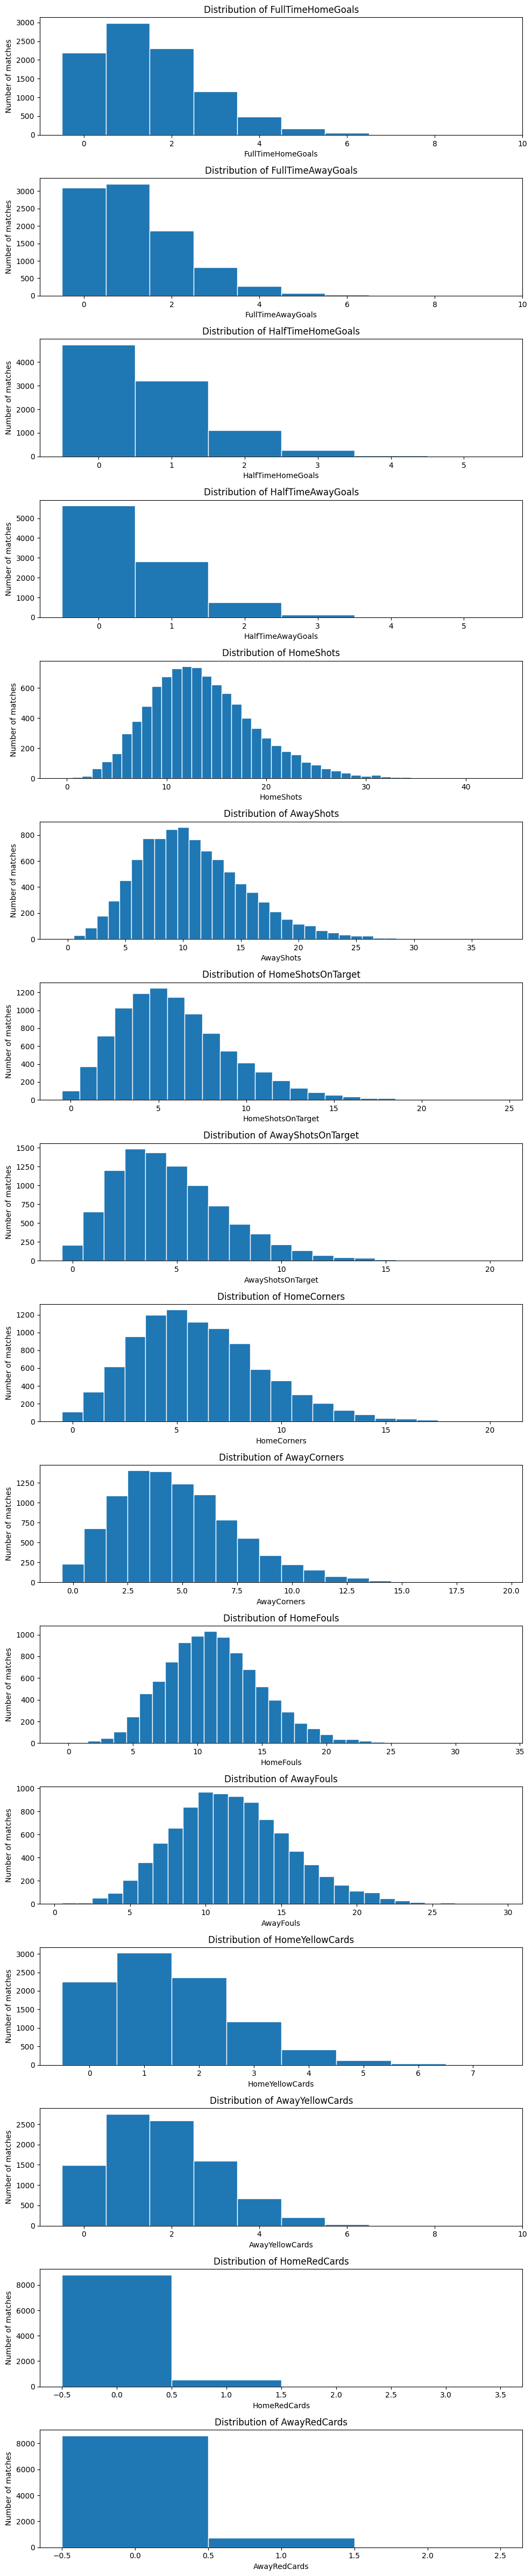

In [15]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
#print(numeric_cols)

fig, axes = plt.subplots(
    nrows=len(numeric_cols),
    ncols=1,
    figsize=(10, 3 * len(numeric_cols)),
    squeeze=False
)

for ax, col in zip(axes[:, 0], numeric_cols):
    values = df[col].dropna()
    bins = np.arange(values.min() - 0.5, values.max() + 1.5, 1)

    ax.hist(values, bins=bins, edgecolor="white")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of matches")

plt.tight_layout()
plt.show()

### 9. Outliers Analysis

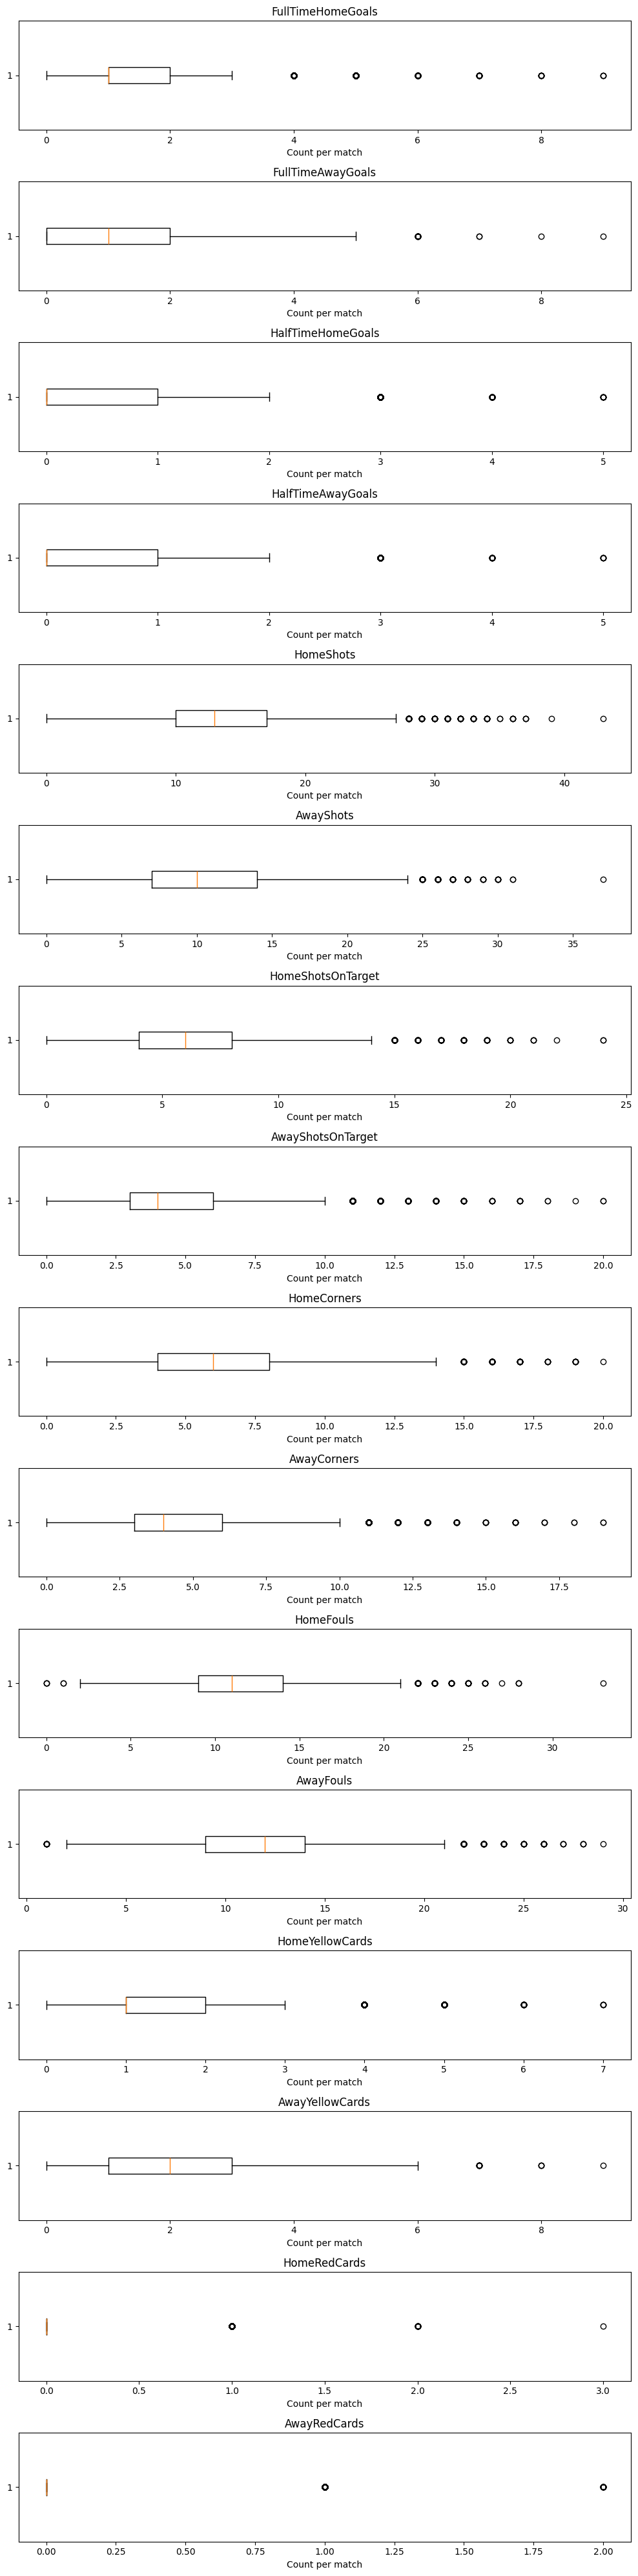

In [16]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

# creating the plots
fig, axes = plt.subplots(
    nrows=len(numeric_cols), #one plot for each numerical column
    ncols=1, # arrange them vertically
    figsize=(10, 2.5 * len(numeric_cols)), # set the overall figure dimensions 
    squeeze=False # keep axes as a two-dimensional array, even if there's only one plot 
)

# drawing each box plot
for ax, col in zip(axes[:, 0], numeric_cols): # zip: pairs each subplot with a numerical column
    ax.boxplot(df[col].dropna(), vert=False) # draws the boxplot
    ax.set_title(col)
    ax.set_xlabel("Count per match")

plt.tight_layout()
plt.show()
# medianL 1 -> half of the matches got one goal or fewer scored by the home team
# Q1 = 1 and Q3 = 2 the middle 50% of observations lie aprroximately between 1 and 2 goals
# whiskers extend from 0 to 3 they are the lowest and highest non-outlier observations
# circles: outliers

- Goals: Most matches have low goal counts. High-scoring matches appear as outliers, but may be valid.

- Shots, shots on target, and corners: Most matches fall in the middle ranges shown by the boxes; unusually high totals are less common. Check - the three shots-on-target inconsistencies separately—an outlier dot alone doesn’t mean an error.

- Fouls and yellow cards: Most matches have moderate counts, with some matches having unusually high counts.

- Red cards: The median is zero because most matches have no red cards. A match with one or more red cards can show as an outlier simply because red cards are rare.

### 10. Correlation Analysis

In [17]:
corr = df[explore_cols].corr()

fig, ax = plt.subplots(figsize=(14, 12))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
fig.colorbar(image, ax=ax, label="Correlation")

ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)

# Print each correlation value inside its square
for row in range(len(corr)):
    for col in range(len(corr.columns)):
        value = corr.iloc[row, col]
        text_color = "white" if abs(value) >= 0.55 else "black"
        ax.text(col, row, f"{value:.2f}",
                ha="center", va="center",
                color=text_color, fontsize=8)

ax.set_title("Correlation between match statistics")
plt.tight_layout()
plt.show()

NameError: name 'explore_cols' is not defined

- Half-time and full-time goals for the same team **(0.69)**: This strong positive relationship is expected because the half-time goals are included 
in the final score. A team that has already scored at half-time often finishes with more goals, though it may score more afterward.

- Fouls and yellow cards for the same team **(home 0.33; away 0.35)**: This positive relationship is also expected. More fouls create more chances for a referee to issue a yellow card. It is only moderate because not every foul earns a card, and some cards are given for other reasons.

- Home and away corners **(−0.25)**: The weak negative relationship could reflect one team attacking more while the other spends more time defending. But corner counts are not a strict trade-off, so the correlation doesn’t prove that explanation.

- Red cards and most other statistics: These relationships are weak. Red cards are uncommon, so there are few examples to reveal a consistent pattern.

### Phase 1 Conclusion

- The dataset loaded successfully and contains 9,380 matches and 22 columns. 
- No missing values or duplicate matches were found, and the full-time and half-time result labels agree with the recorded scores. 
- The date column was converted to a date format for analysis. 
- The histograms and boxplots show that low goal totals and zero red cards are common, while unusually high values are less common. These outliers may be valid matches and should not be removed automatically. 
- The correlation heatmap shows that most relationships between statistics are weak; the clearest relationships are between each team's half-time and full-time goals, which is expected.

The data audit found three seasons with fewer than 380 recorded matches: 2003/04 and 2004/05 have 335 each, and 2024/25 has 350. 
- Three matches also contain shots-on-target values greater than total shots. These records need to be checked against the source before using them in analyses of season trends or shot statistics. 

Phase 1 describes the dataset and its limitations; it does not yet determine whether home advantage has changed.

## Phase 2: **Descriptive Analysis of Home Advantage**

### 1. Percentage of home wins, Away wins, and Draw

In [ ]:
result_counts = df["FullTimeResult"].value_counts().reindex(
    ["H", "D", "A"], fill_value=0
)

result_summary = pd.DataFrame({
    "Matches": result_counts,
    "Percentage": result_counts / len(df) * 100
})

result_summary.index = ["Home win", "Draw", "Away win"]
display(result_summary.round(2))

,Matches,Percentage
Home win,4299,45.83
Draw,2313,24.66
Away win,2768,29.51


Of the 9,380 recorded matches, **45.83%** were home wins, **29.51%** were away wins, and **24.66%** were draws. 
Home wins were the most common outcome and occurred **16.32%** points more often than away wins. This suggests an overall home advantage in match results, though it doesn’t show how that advantage changed by season.

### 2. Average full-time goals scored by home and away teams 

In [ ]:
goal_comparison = pd.DataFrame({
    "Average goals per match": {
        "Home team": df["FullTimeHomeGoals"].mean(),
        "Away team": df["FullTimeAwayGoals"].mean()
    }
})

display(goal_comparison)

,Average goals per match
Home team,1.535394
Away team,1.182623


Home teams scored **1.535394** goals per match on average, compared with **1.182623** for away teams. 

### 3. Goal difference

In [ ]:
goal_difference = (
    df["FullTimeHomeGoals"] - df["FullTimeAwayGoals"]
)

print(f"Average goal difference: {goal_difference.mean()}")

Average goal difference: 0.352771855010661


The average goal difference is **+0.35** goals per match. This means home teams scored about a third of a goal more than away teams per match on average, a descriptive sign of a home scoring advantage.

### 4. How often each side scored

In [ ]:
home_scored = (df["FullTimeHomeGoals"] > 0).sum()
away_scored = (df["FullTimeAwayGoals"] > 0).sum()
total_matches = len(df)

scoring_summary = pd.DataFrame({
    "Matches scored": [home_scored, away_scored],
    "Scoring percentage": [
        home_scored / total_matches * 100,
        away_scored / total_matches * 100
    ]
}, index=["Home team", "Away team"])

display(scoring_summary.round(2))

,Matches scored,Scoring percentage
Home team,7194,76.70
Away team,6278,66.93


- Home teams scored at least one goal in **7,194** of 9380 matches **(76.70%)**. 
- Away teams scored in **6,278** of 9380 matches **(66.93%)**. 

Home teams therefore scored in **9.77** percentage points more matches than away teams. This describes how often each side scored, not how many goals they scored.

### 5. Points per match at home and away

In [ ]:
home_points = np.where(
    df["FullTimeResult"] == "H", 3,
    np.where(df["FullTimeResult"] == "D", 1, 0)
)

away_points = np.where(
    df["FullTimeResult"] == "A", 3,
    np.where(df["FullTimeResult"] == "D", 1, 0)
)

points_summary = pd.DataFrame({
    "Total points": [home_points.sum(), away_points.sum()],
    "Average points per match": [home_points.mean(), away_points.mean()]
}, index=["Home team", "Away team"])

display(points_summary)

,Total points,Average points per match
Home team,15210,1.621535
Away team,10617,1.131876


home teams earned **1.62** points per match on average, compared with **1.13** for away teams—a difference of about **0.49** points per match. This indicates that home teams earned more points overall, consistent with the higher home-win percentage. These are overall averages across the dataset, not season-by-season results.

### 6. Yello cards

In [ ]:
yellow_summary = pd.DataFrame({
    "Average yellow cards per match": {
        "Home team": df["HomeYellowCards"].mean(),
        "Away team": df["AwayYellowCards"].mean()
    }
})

display(yellow_summary.round(2))

,Average yellow cards per match
Home team,1.47
Away team,1.79


Home teams received **1.47** yellow cards per match on average; away teams received **1.79**. So away teams received about **0.32** more yellow cards per match in this dataset. This is an overall difference, not proof that referees favor home teams.

### 7. Red cards

In [ ]:
red_summary = pd.DataFrame({
    "Average red cards per match": {
        "Home team": df["HomeRedCards"].mean(),
        "Away team": df["AwayRedCards"].mean()
    }
})

display(red_summary.round(3))

,Average red cards per match
Home team,0.062
Away team,0.085


Away teams received **0.085** red cards per match, compared with **0.062** for home teams. That’s a difference of **0.023** per match, or about **2.3** more red cards per 100 matches for away teams. Red cards are rare, so this is a small overall difference; it doesn’t by itself show that referees favored home teams.

### Question 1: Do the yellow/red card results suggest that referees favored home teams?

**Answer:** Away teams received more cards on average: This shows a card difference by venue, but it does not prove that referees favored home teams. The difference could also relate to fouls or match situations, and the dataset does not identify individual referees.

### Question 2: Could the card difference be related to fouls?

**Answer:** Possibly. Fouls and yellow cards had moderate positive correlations: **0.33** for home teams and **0.35** for away teams. This means teams with more fouls tended to receive more yellow cards. The dataset counts fouls without showing how serious they were. Not every foul results in a card, and some cards are given for actions such as dissent or time-wasting. So the correlation suggests a possible relationship, but does not explain the card difference by itself. It does not prove that fouls caused the cards.

### 8. Plot the meausers we found season by season

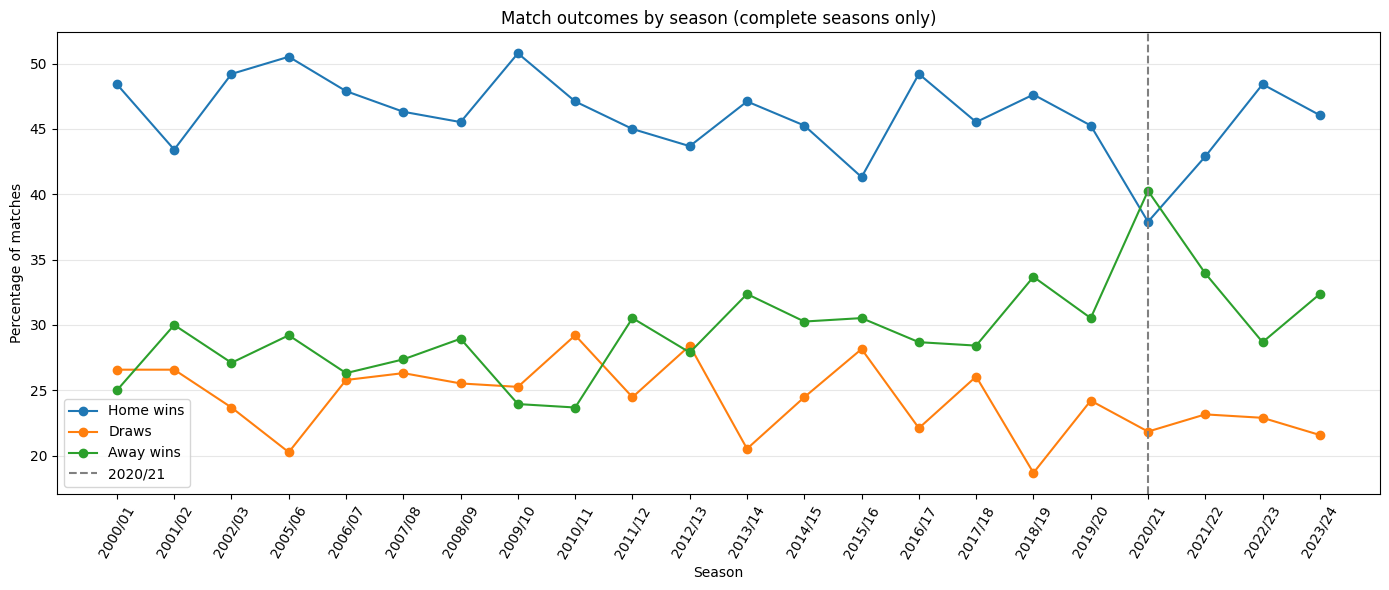

In [ ]:
## Wins

season_results = df.groupby("Season").agg(
    Matches=("FullTimeResult", "size"),
    HomeWinPct=("FullTimeResult", lambda s: s.eq("H").mean() * 100),
    DrawPct=("FullTimeResult", lambda s: s.eq("D").mean() * 100),
    AwayWinPct=("FullTimeResult", lambda s: s.eq("A").mean() * 100)
)

# Keep full seasons for the plot; short seasons could distort the trend.
complete = season_results[season_results["Matches"] == 380]
seasons = complete.index.tolist()
x = np.arange(len(seasons))

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(x, complete["HomeWinPct"], marker="o", label="Home wins")
ax.plot(x, complete["DrawPct"], marker="o", label="Draws")
ax.plot(x, complete["AwayWinPct"], marker="o", label="Away wins")

# Mark the 2020/21 season
ax.axvline(seasons.index("2020/21"), color="gray", linestyle="--",
           label="2020/21")

ax.set_xticks(x)
ax.set_xticklabels(seasons, rotation=60)
ax.set_ylabel("Percentage of matches")
ax.set_xlabel("Season")
ax.set_title("Match outcomes by season (complete seasons only)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In most seasons shown, home wins were the most common result. In **2020/21**, marked by the dashed line, that pattern changed: about 38% of matches were home wins, **40%** were away wins, and **22%** were draws. In the seasons afterward, home wins became the most common result again.

That **2020/21** change is consistent with a possible reduction in home advantage during the season with few spectators

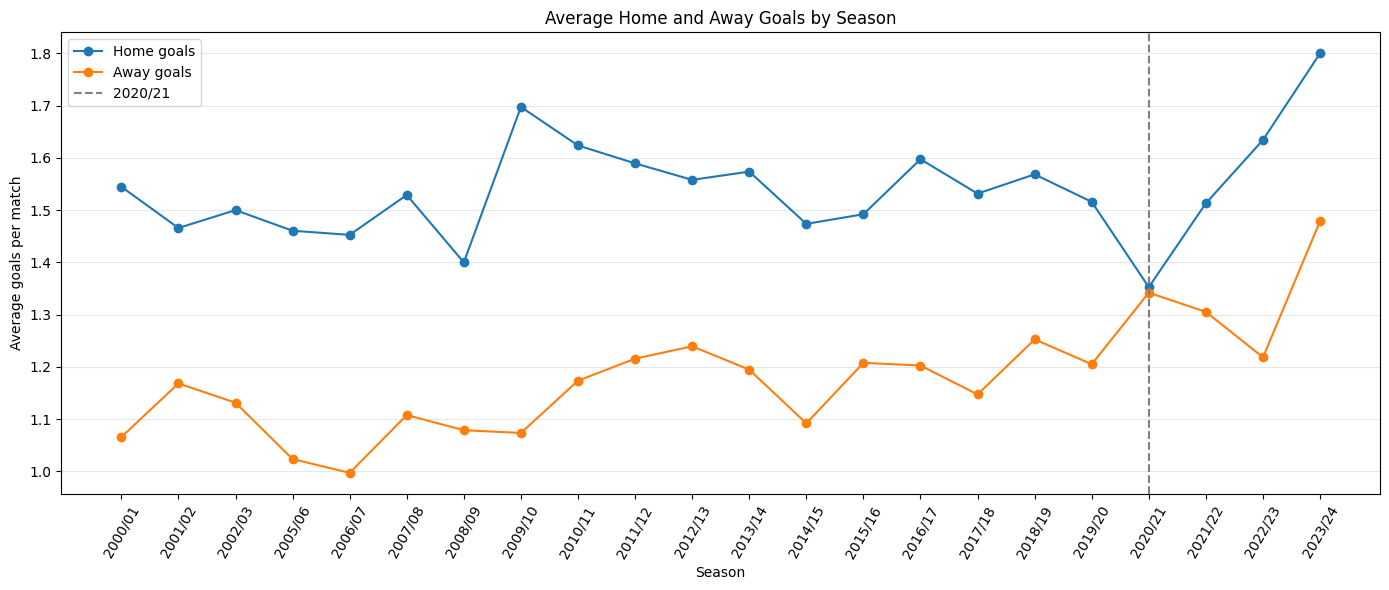

In [ ]:

# Goals 

season_goals = df.groupby("Season").agg(
    Matches=("Season", "size"),
    AvgHomeGoals=("FullTimeHomeGoals", "mean"),
    AvgAwayGoals=("FullTimeAwayGoals", "mean")
)

season_goals = season_goals[season_goals["Matches"] == 380]

seasons = season_goals.index.tolist()
x = np.arange(len(seasons))

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(x, season_goals["AvgHomeGoals"], marker="o", label="Home goals")
ax.plot(x, season_goals["AvgAwayGoals"], marker="o", label="Away goals")
ax.axvline(seasons.index("2020/21"), color="gray", linestyle="--",
           label="2020/21")

ax.set_xticks(x)
ax.set_xticklabels(seasons, rotation=60)
ax.set_xlabel("Season")
ax.set_ylabel("Average goals per match")
ax.set_title("Average Home and Away Goals by Season")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

- In most seasons shown, the home team’s average goals are higher than the away team’s. 
- In **2020/21**, marked by the dashed line, they were almost equal: about 1.35 home goals and 1.34 away goals per match. 
- The home average was higher again in the seasons that followed. 
- Among the seasons shown, 2023/24 had the highest averages: about 1.80 home goals and 1.48 away goals per match.

In **2020/21**, average home and away goals were almost equal. This season took place during the COVID-19 pandemic, when Premier League matches were played mostly behind closed doors. Without the usual home crowd, home teams may have had less of a scoring advantage.



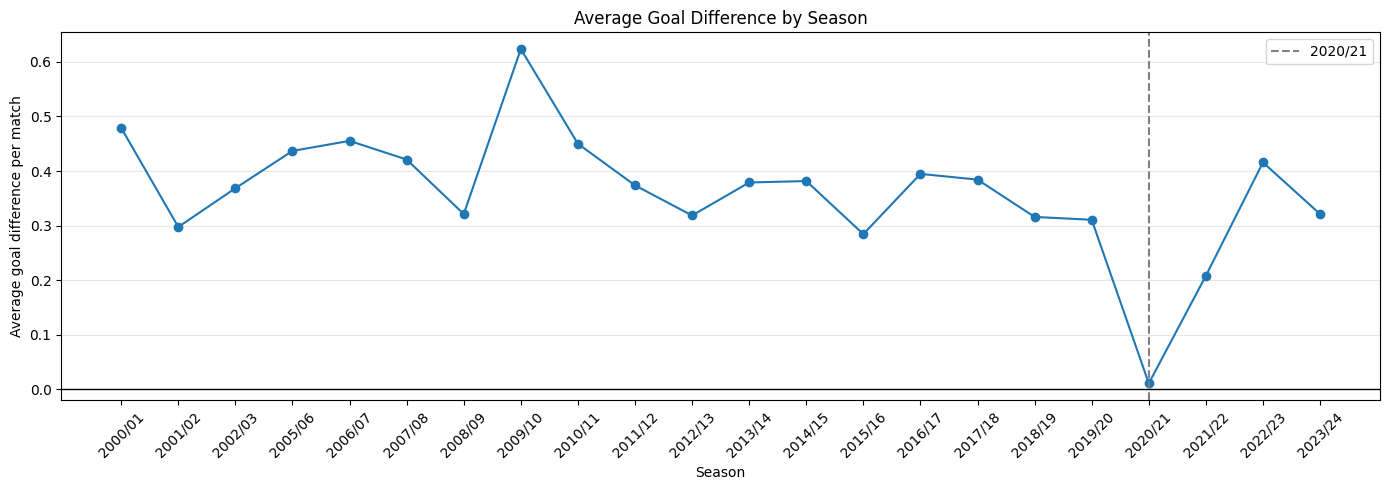

In [ ]:
# Goal difference 
season_goal_diff = df.groupby("Season").agg(
    Matches=("Season", "size"),
    AvgHomeGoals=("FullTimeHomeGoals", "mean"),
    AvgAwayGoals=("FullTimeAwayGoals", "mean")
)

# Calculate home-minus-away goal difference
season_goal_diff["AvgGoalDifference"] = (
    season_goal_diff["AvgHomeGoals"] - season_goal_diff["AvgAwayGoals"]
)

# Keep complete seasons only
season_goal_diff = season_goal_diff[season_goal_diff["Matches"] == 380]

seasons = season_goal_diff.index.tolist()
x = np.arange(len(seasons))

# Plot
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(x, season_goal_diff["AvgGoalDifference"], marker="o")
ax.axhline(0, color="black", linewidth=1)
ax.axvline(
    seasons.index("2020/21"),
    color="gray",
    linestyle="--",
    label="2020/21"
)

ax.set_xticks(x)
ax.set_xticklabels(seasons, rotation=45)
ax.set_xlabel("Season")
ax.set_ylabel("Average goal difference per match")
ax.set_title("Average Goal Difference by Season")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

The home scoring gap was almost zero in **2020/21—about 0.01** goal per match. It rose to about 0.21 in **2021/22, 0.42** in **2022/23, and 0.32** in **2023/24**. Since most **2020/21** matches were played behind closed doors, this pattern is consistent with the idea that crowd support may contribute to home advantage.

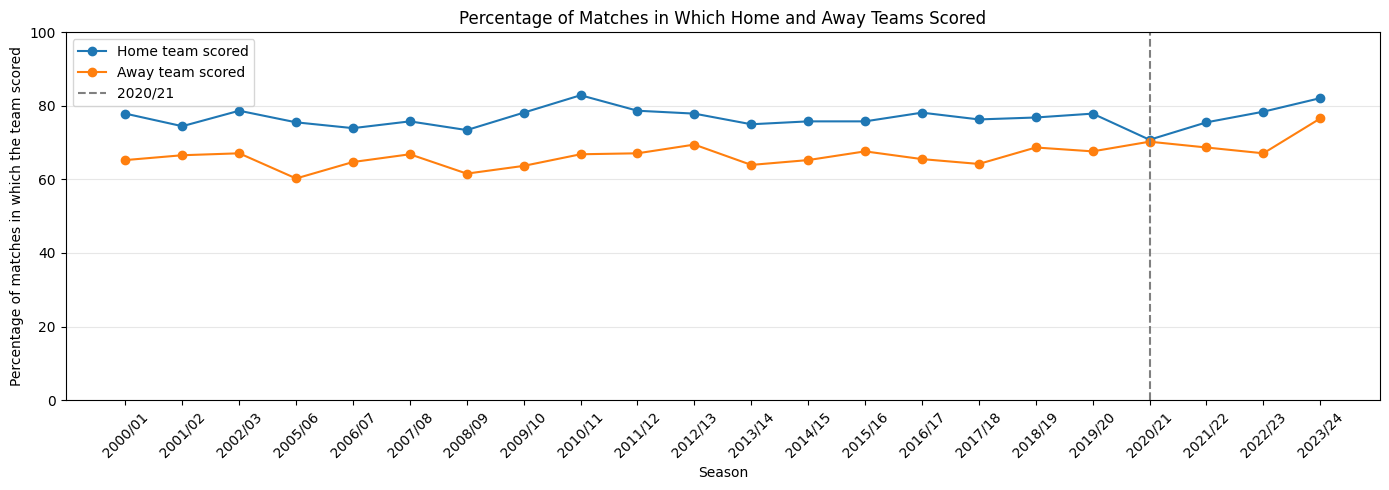

In [ ]:
# How often do home and away teams score per season

season_scoring = df.groupby("Season").agg(
    Matches=("Season", "size"),
    HomeScoredPct=("FullTimeHomeGoals",
                   lambda goals: (goals > 0).mean() * 100),
    AwayScoredPct=("FullTimeAwayGoals",
                   lambda goals: (goals > 0).mean() * 100)
)

# Keep complete seasons only
season_scoring = season_scoring[season_scoring["Matches"] == 380]

seasons = season_scoring.index.tolist()
x = np.arange(len(seasons))

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(x, season_scoring["HomeScoredPct"], marker="o", label="Home team scored")
ax.plot(x, season_scoring["AwayScoredPct"], marker="o", label="Away team scored")
ax.axvline(
    seasons.index("2020/21"),
    color="gray",
    linestyle="--",
    label="2020/21"
)

ax.set_xticks(x)
ax.set_xticklabels(seasons, rotation=45)
ax.set_xlabel("Season")
ax.set_ylabel("Percentage of matches in which the team scored")
ax.set_ylim(0, 100)
ax.set_title("Percentage of Matches in Which Home and Away Teams Scored")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In **2020/21**, marked by the dashed line, both teams scored in about **71%** of matches. The home scoring rate dropped while the away rate rose slightly, so the difference almost disappeared. In the following seasons, the home scoring rate became higher again. This pattern is consistent with a possible reduction in home advantage during the season with few spectators

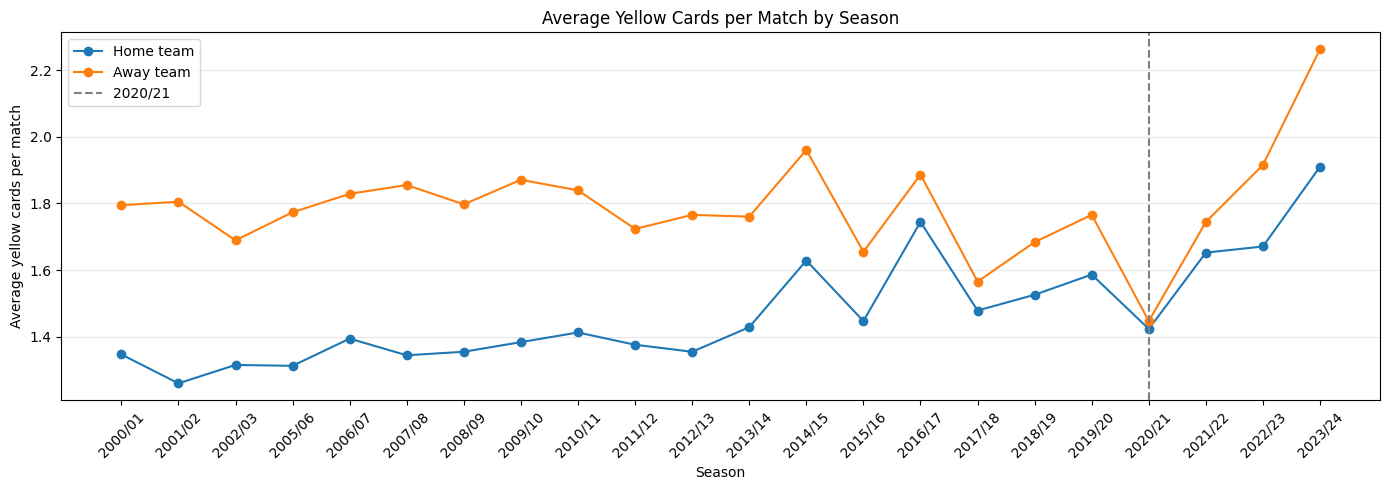

In [ ]:
# Yellow cards
season_yellow = df.groupby("Season").agg(
    Matches=("Season", "size"),
    HomeYellowAvg=("HomeYellowCards", "mean"),
    AwayYellowAvg=("AwayYellowCards", "mean")
)

# Keep complete seasons only
season_yellow = season_yellow[season_yellow["Matches"] == 380]

seasons = season_yellow.index.tolist()
x = np.arange(len(seasons))

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(x, season_yellow["HomeYellowAvg"], marker="o", label="Home team")
ax.plot(x, season_yellow["AwayYellowAvg"], marker="o", label="Away team")
ax.axvline(
    seasons.index("2020/21"),
    color="gray",
    linestyle="--",
    label="2020/21"
)

ax.set_xticks(x)
ax.set_xticklabels(seasons, rotation=45)
ax.set_xlabel("Season")
ax.set_ylabel("Average yellow cards per match")
ax.set_title("Average Yellow Cards per Match by Season")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Away teams received more yellow cards per match than home teams in nearly every season shown. In 2020/21, marked by the dashed line, the averages were almost equal—about 1.45 away and 1.42 home yellow cards per match. After that season, the gap widened again, and in 2023/24 the away-team average rose to about 2.26, compared with 1.91 for home teams.

This describes a difference in card averages; it does not prove referee bias or explain why the difference occurred. Cards can depend on the fouls and incidents in each match, among other factors.

## Phase 2: Conclusion

Across **9,380 matches**, home teams won **45.83%** of matches, compared with **29.51%** for away teams; **24.66%** ended in a draw. Home teams averaged more goals (**1.54 vs. 1.18 per match**) and points (**1.62 vs. 1.13 per match**). They also scored in a greater share of matches (**76.70% vs. 66.93%**).

In **2020/21**, home and away win percentages and average goals were nearly equal. Most matches that season were played behind closed doors because of COVID-19 ([Premier League source](https://www.premierleague.com/ar/news/1682374)). This pattern may suggest that crowds contribute to home advantage, but it does not prove they caused the change.

Away teams received more yellow cards (**1.79 vs. 1.47 per match**) and red cards (**0.085 vs. 0.062 per match**) on average. These differences alone do not prove referee bias.

**Overall, home advantage was present across the dataset, weakened in 2020/21, and appeared again in later seasons.**

## Phase 3: **Statistical Models and Pattern Analysis**


## Phase 4: **Match-Outcome Prediction**

## Phase 5: **Interpretation and Presentation**